In [1]:
import os.path as osp
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
from ipywidgets import IntSlider, BoundedIntText, HBox, Layout, jslink, interactive_output
from IPython.display import display
from scipy.signal import welch

In [2]:
filename = Path("20261015_15h05m32_dsum_coincidence_H62_NZKF_time_25V_180s.csv")
filedir = Path("~/Desktop/UCSDPDCv2/data/DSUM_101526")

file = (filedir / filename).expanduser()
print(f"Running file at {file}")

data = pd.read_csv(file, delimiter=';')
print(f"Lines read: {len(data):,} with columns {list(data.columns)}")

Running file at /Users/pknauss/Desktop/UCSDPDCv2/data/DSUM_101526/20261015_15h05m32_dsum_coincidence_H62_NZKF_time_25V_180s.csv
Lines read: 909,460 with columns ['pdcIdx', 'frameIdx', 'dataIdx', 'dsum']


# Per-Frame Data

In [3]:
# Sort the data on frame and pdc for easy nested looping
df = {
    frame: {pdc: data for pdc, data in frame_data.groupby("pdcIdx")}
    for frame, frame_data in data.groupby("frameIdx")
}

print(f"Read {len(df):,} frames across {len(df[0])} PDCs")

Read 1,829 frames across 4 PDCs


### Check average counts across frames

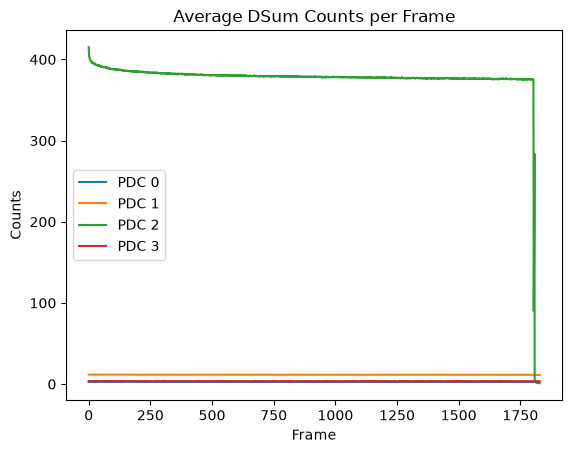

In [4]:
means = []
for i, frame in df.items():
    mean = {}
    for j, pdc in frame.items():
        index = pdc["dataIdx"].to_numpy()
        dsum = pdc["dsum"].to_numpy()
        mean[j] = np.mean(dsum)
    means.append(mean)

for pdc in np.arange(len(df[0])):
    pdc_mean_list = []
    for mean_set in means:
        try: mean = mean_set[pdc]
        except: pass
        pdc_mean_list.append(mean)
    plt.plot(pdc_mean_list, label=f"PDC {pdc}")
plt.legend()
plt.title("Average DSum Counts per Frame")
plt.xlabel("Frame")
plt.ylabel("Counts")
plt.show()

### Interactive Per-Frame Plotter

In [5]:
def show(frame):
    plt.figure(figsize=(8, 3))
    for pdc, d in df[frame].items():
        plt.plot(d["dataIdx"], d["dsum"], label=f"PDC {pdc}")
    plt.title(f"Frame {frame}")
    plt.xlabel("Index")
    plt.ylabel("DSum")
    plt.yscale("log")
    plt.legend()
    plt.show()

fr = sorted(df)
slider = IntSlider(min=fr[0], max=fr[-1], continuous_update=False, layout=Layout(width="700px"))
box = BoundedIntText(min=fr[0], max=fr[-1], layout=Layout(width="90px"))
jslink((slider, "value"), (box, "value"))

display(HBox([slider, box]), interactive_output(show, {"frame": slider}))

Output()

### Interactive Per-Frame FFT

In [9]:
def show_psd(frame):
    plt.figure(figsize=(8, 3))
    for pdc, d in df.get(frame, {}).items():
        f, p = welch(d["dsum"].to_numpy(), fs=1e8, nperseg=100, window="hann", detrend="constant")
        plt.plot(f / 1e6, p, label=f"PDC {pdc}")
    plt.title(f"Frame {frame}: PSD")
    plt.xlabel("Frequency (MHz)")
    plt.ylabel("PSD (dsum² / Hz)")
    plt.yscale("log")
    plt.legend()
    plt.show()


fr = sorted(df)
slider = IntSlider(min=fr[0], max=fr[-1], continuous_update=False, layout=Layout(width="700px"))
box = BoundedIntText(min=fr[0], max=fr[-1], layout=Layout(width="90px"))
jslink((slider, "value"), (box, "value"))

display(HBox([slider, box]), interactive_output(show_psd, {"frame": slider}))

Output()